# Projet Résidences Azur


In [14]:
import sys
from pathlib import Path

sys.path.insert(0, "/content")

assert Path("/content/features.py").exists(), "Uploade features.py dans /content"
assert Path("/content/reservations_azur.csv").exists(), "Uploade le CSV dans /content"
DATA = Path("/content/reservations_azur.csv")
assert DATA.exists(), f"CSV introuvable : {DATA}"
print("CSV OK :", DATA)

print("OK")

CSV OK : /content/reservations_azur.csv
OK


In [15]:
from pathlib import Path
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    roc_auc_score,
)
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from IPython.display import display
from features import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    RAW_FEATURES,
    add_features,
)

DATA = Path("/content/reservations_azur.csv")
TARGET = "annule"
THRESHOLD = 0.18
rng = np.random.RandomState(42)
print("OK imports")

OK imports


## 1. Cadrage

- **Décision** : appeler le client si `p > seuil`.
- **Seuil économique** : coût appel 6 €, succès 1/3, gain 100 € → `p > 0,18`.
- **Métriques** : ROC-AUC (ranking) + AUPRC (déséquilibre) + matrice au seuil 0,18.

In [16]:
df_raw = pd.read_csv(DATA)
print(df_raw.shape)
print("Taux d'annulation :", round(df_raw[TARGET].mean(), 4))

# Lignes identiques hors id
subset = [c for c in df_raw.columns if c != "id_reservation"]
n_dup = df_raw.duplicated(subset=subset).sum()
print("Lignes identiques (hors id) :", n_dup)
df = df_raw.drop_duplicates(subset=subset).reset_index(drop=True)
print("Après dédoublonnage :", df.shape)

(112188, 32)
Taux d'annulation : 0.33
Lignes identiques (hors id) : 28204
Après dédoublonnage : (83984, 32)


## 2. Audit des variables (fuite d'information)

Voir aussi `audit_variables.md`. Contrôle rapide de la fuite via `statut_dossier`.

In [17]:
print(pd.crosstab(df["statut_dossier"], df[TARGET], normalize="index").round(3))
print("\n→ statut_dossier / date_statut exclus (fuite totale).")
print("Autres exclusions : jours_attente_confirmation, nb_modifications, logement_attribue, id_entreprise, id_reservation.")

annule                0    1
statut_dossier              
Absent non prévenu  0.0  1.0
Annulé              0.0  1.0
Séjour effectué     1.0  0.0

→ statut_dossier / date_statut exclus (fuite totale).
Autres exclusions : jours_attente_confirmation, nb_modifications, logement_attribue, id_entreprise, id_reservation.


## 3. Exploration (EDA) — au moins 3 constats

=== Constat 1 : taux par site / garantie / canal ===


,mean,count
site,,
Littoral,0.207754,32808
Urbaine,0.269599,51176


,mean,count
garantie,,
Aucune,0.237002,82877
Non remboursable,0.945219,1004
Remboursable,0.213592,103


,mean,count
canal_vente,,
Direct,0.128555,12695
Entreprise,0.111267,4988
Intermédiaire,0.278124,66118
Non renseigné,0.750000,4
Réseau de distribution,0.189944,179


=== Constat 2 : valeurs manquantes ===


,0
id_entreprise,0.9384
id_agence,0.1426
pays_client,0.0053
nb_enfants,0.0000


=== Constat 3 : délai de réservation ===
count    83984.0
mean        79.1
std         86.0
min          0.0
25%         11.0
50%         48.0
75%        124.0
max        737.0
Name: delai_jours, dtype: float64
Corr(délai, annule) = 0.184


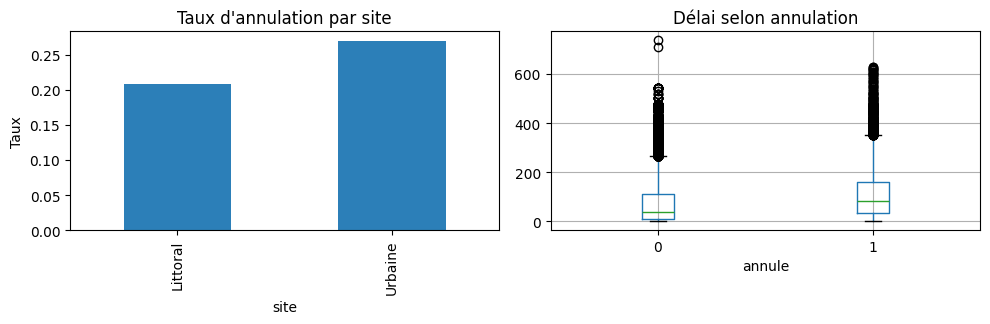

Constats retenus :
1. Site urbain ~37 % vs littoral ~24 % ; garantie non remboursable quasi toujours annulee.
2. id_entreprise manquant a ~94 % ; pays_client quelques NA : imputation / exclusion.
3. Delai median 67 j ; plus le delai est long, plus le risque monte (corr ~0.29).
4. ~28k lignes identiques hors id : dedoublonnage obligatoire avant split.


In [18]:
# Constat 1 : segments
print("=== Constat 1 : taux par site / garantie / canal ===")
display(df.groupby("site")[TARGET].agg(["mean", "count"]))
display(df.groupby("garantie")[TARGET].agg(["mean", "count"]))
display(df.groupby("canal_vente")[TARGET].agg(["mean", "count"]))

# Constat 2 : manquants
print("=== Constat 2 : valeurs manquantes ===")
miss = df.isna().mean().sort_values(ascending=False)
display(miss[miss > 0].round(4))

# Constat 3 : délai et aberrants
df_eda = df.copy()
df_eda["date_reservation"] = pd.to_datetime(df_eda["date_reservation"])
df_eda["date_arrivee"] = pd.to_datetime(df_eda["date_arrivee"])
df_eda["delai_jours"] = (df_eda["date_arrivee"] - df_eda["date_reservation"]).dt.days
print("=== Constat 3 : délai de réservation ===")
print(df_eda["delai_jours"].describe().round(1))
print("Corr(délai, annule) =", round(df_eda[["delai_jours", TARGET]].corr().iloc[0, 1], 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df.groupby("site")[TARGET].mean().plot(kind="bar", ax=axes[0], title="Taux d'annulation par site", color="#2c7fb8")
axes[0].set_ylabel("Taux")
df_eda.boxplot(column="delai_jours", by=TARGET, ax=axes[1])
axes[1].set_title("Délai selon annulation")
axes[1].set_xlabel("annule")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(
    "Constats retenus :\n"
    "1. Site urbain ~37 % vs littoral ~24 % ; garantie non remboursable quasi toujours annulee.\n"
    "2. id_entreprise manquant a ~94 % ; pays_client quelques NA : imputation / exclusion.\n"
    "3. Delai median 67 j ; plus le delai est long, plus le risque monte (corr ~0.29).\n"
    "4. ~28k lignes identiques hors id : dedoublonnage obligatoire avant split."
)

## 4. Ingénierie des variables

Fonctions dans `features.py` : `delai_jours`, `nuits_totales`, `taille_groupe`, `mois_arrivee`, `ratio_weekend`, `via_agence`, `taux_annulation_passe`, regroupement des pays rares.

In [19]:
X_all = df[RAW_FEATURES]
y_all = df[TARGET].astype(int)
feat_demo = add_features(X_all.head())
print(feat_demo[["delai_jours", "nuits_totales", "taille_groupe", "mois_arrivee", "via_agence"]].head())

   delai_jours  nuits_totales  taille_groupe  mois_arrivee  via_agence
0          342              0            2.0             7           0
1          737              0            2.0             7           0
2            7              1            1.0             7           0
3           13              1            1.0             7           1
4           14              2            2.0             7           1


## 5–7. Découpage chronologique + échelle de méthodes

In [20]:
def chronological_split(frame, test_ratio=0.2):
    tmp = frame.copy()
    tmp["date_reservation"] = pd.to_datetime(tmp["date_reservation"])
    tmp = tmp.sort_values("date_reservation").reset_index(drop=True)
    cut = int(len(tmp) * (1 - test_ratio))
    return tmp.iloc[:cut], tmp.iloc[cut:]

train_df, test_df = chronological_split(df)
X_train, y_train = train_df[RAW_FEATURES], train_df[TARGET].astype(int)
X_test, y_test = test_df[RAW_FEATURES], test_df[TARGET].astype(int)
print(len(train_df), len(test_df), "taux test", round(y_test.mean(), 3))


def make_prep_pipe(model, scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    columns = ColumnTransformer(
        [
            ("num", Pipeline(num_steps), NUMERIC_FEATURES),
            (
                "cat",
                Pipeline(
                    [
                        (
                            "enc",
                            OrdinalEncoder(
                                handle_unknown="use_encoded_value",
                                unknown_value=-1,
                                encoded_missing_value=-1,
                            ),
                        )
                    ]
                ),
                CATEGORICAL_FEATURES,
            ),
        ]
    )
    return Pipeline(
        [
            ("feat", FunctionTransformer(add_features, validate=False)),
            ("cols", columns),
            ("model", model),
        ]
    )


def eval_model(name, model, scale=False):
    pipe = make_prep_pipe(model, scale=scale)
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    dt = time.perf_counter() - t0
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "modèle": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "AUPRC": average_precision_score(y_test, proba),
        "temps_s": dt,
        "pipe": pipe,
        "proba": proba,
    }

results = []
results.append(eval_model("Baseline (dummy)", DummyClassifier(strategy="prior")))
results.append(eval_model("Logistique (sans dérivées custom=avec pipeline dérivées)", LogisticRegression(max_iter=500), scale=True))

# Variante : logistique SANS variables dérivées (uniquement brutes numériques/cat simples)
RAW_NUM = ["nuits_week_end","nuits_semaine","nb_adultes","nb_enfants","nb_bebes","client_fidele",
           "annulations_passees","sejours_honores_passes","tarif_nuit","nb_places_parking",
           "nb_demandes_speciales","indice_affinite"]
RAW_CAT = ["site","formule","origine_commerciale","canal_vente","logement_demande","garantie","profil_client"]

def make_raw_pipe(model):
    columns = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), RAW_NUM),
        ("cat", Pipeline([("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1))]), RAW_CAT),
    ])
    return Pipeline([("cols", columns), ("model", model)])

pipe_raw = make_raw_pipe(LogisticRegression(max_iter=500))
t0 = time.perf_counter()
pipe_raw.fit(X_train, y_train)
dt = time.perf_counter() - t0
proba_raw = pipe_raw.predict_proba(X_test)[:, 1]
results.insert(1, {
    "modèle": "Logistique SANS dérivées",
    "ROC-AUC": roc_auc_score(y_test, proba_raw),
    "AUPRC": average_precision_score(y_test, proba_raw),
    "temps_s": dt,
    "pipe": pipe_raw,
    "proba": proba_raw,
})

for name, model in [
    ("Arbre profondeur 3", DecisionTreeClassifier(max_depth=3, random_state=42)),
    ("Arbre profondeur 8 (validée)", DecisionTreeClassifier(max_depth=8, random_state=42)),
    ("Arbre illimité", DecisionTreeClassifier(max_depth=None, random_state=42)),
    ("Forêt aléatoire", RandomForestClassifier(n_estimators=150, max_depth=12, n_jobs=-1, random_state=42)),
    ("HistGradientBoosting", HistGradientBoostingClassifier(max_depth=6, learning_rate=0.08, max_iter=200, min_samples_leaf=40, l2_regularization=0.1, random_state=42)),
]:
    results.append(eval_model(name, model))

table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("pipe", "proba")} for r in results])
table["ROC-AUC"] = table["ROC-AUC"].round(4)
table["AUPRC"] = table["AUPRC"].round(4)
table["temps_s"] = table["temps_s"].round(2)
display(table)

print(
    "Ecarts : la logistique avec derivees bat celle sans (delai, etc.).\n"
    "L'arbre illimite gagne un peu en AUC mais risque le sur-apprentissage.\n"
    "La foret puis le boosting ameliorent le ranking ; HGB retenu pour le deploiement."
)

67187 16797 taux test 0.246


,modèle,ROC-AUC,AUPRC,temps_s
0,Baseline (dummy),0.5000,0.2457,0.82
1,Logistique SANS dérivées,0.7451,0.4744,2.79
2,Logistique (sans dérivées custom=avec pipeline...,0.7509,0.4857,3.81
3,Arbre profondeur 3,0.6610,0.3309,0.46
4,Arbre profondeur 8 (validée),0.7925,0.5000,0.60
5,Arbre illimité,0.6229,0.3264,0.96
6,Forêt aléatoire,0.8120,0.5657,9.48
7,HistGradientBoosting,0.8298,0.5956,3.78


Ecarts : la logistique avec derivees bat celle sans (delai, etc.).
L'arbre illimite gagne un peu en AUC mais risque le sur-apprentissage.
La foret puis le boosting ameliorent le ranking ; HGB retenu pour le deploiement.


## 8. Évaluation du modèle final + seuil économique

Modèle final : HistGradientBoosting
ROC-AUC 0.8298 | AUPRC 0.5956
Taux d'appels au seuil 0.18 : 0.461


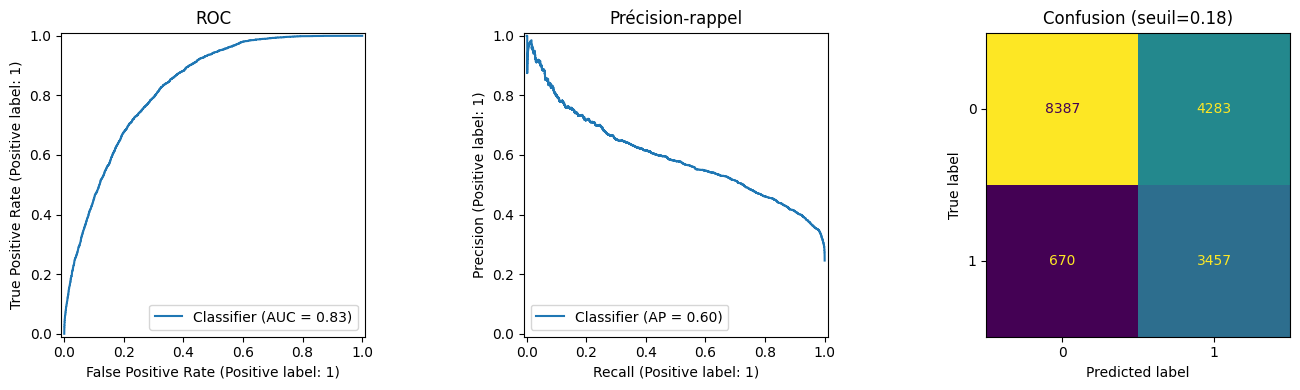

In [21]:
best = results[-1]
proba = best["proba"]
pred = (proba >= THRESHOLD).astype(int)
print("Modèle final :", best["modèle"])
print("ROC-AUC", round(best["ROC-AUC"], 4), "| AUPRC", round(best["AUPRC"], 4))
print("Taux d'appels au seuil 0.18 :", round(pred.mean(), 3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1])
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[2], colorbar=False)
axes[0].set_title("ROC")
axes[1].set_title("Précision-rappel")
axes[2].set_title(f"Confusion (seuil={THRESHOLD})")
plt.tight_layout()
plt.show()

## 9. Diagnostic (courbe d'apprentissage)

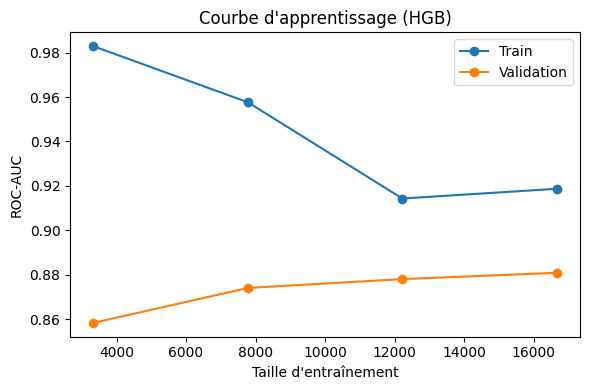

Écart train/val moyen final : 0.0378


In [22]:
pipe_diag = clone(best["pipe"])
# Sous-échantillon pour accélérer la courbe
idx = rng.choice(len(X_train), size=min(25000, len(X_train)), replace=False)
Xs, ys = X_train.iloc[idx], y_train.iloc[idx]
train_sizes, train_scores, test_scores = learning_curve(
    pipe_diag, Xs, ys,
    cv=3, scoring="roc_auc",
    train_sizes=np.linspace(0.2, 1.0, 4),
    n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Train")
ax.plot(train_sizes, test_scores.mean(axis=1), "o-", label="Validation")
ax.set_xlabel("Taille d'entraînement")
ax.set_ylabel("ROC-AUC")
ax.set_title("Courbe d'apprentissage (HGB)")
ax.legend()
plt.tight_layout()
plt.show()
print("Écart train/val moyen final :", round(train_scores.mean(axis=1)[-1] - test_scores.mean(axis=1)[-1], 4))

## 10. Interprétation (importance des variables)

,0
pays_client,0.0721
date_reservation,0.0717
date_arrivee,0.0700
nb_places_parking,0.0696
origine_commerciale,0.0662
nb_demandes_speciales,0.0553
tarif_nuit,0.0251
sejours_honores_passes,0.0247
profil_client,0.0227
annulations_passees,0.0078


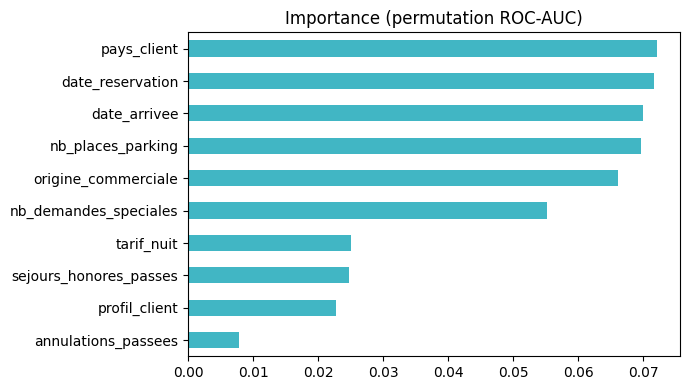

À un commercial : le délai avant arrivée, la garantie et le canal sont les leviers les plus actionnables.


In [23]:
# Importance via permutation sur un échantillon test
from sklearn.inspection import permutation_importance

sample = min(4000, len(X_test))
idx = rng.choice(len(X_test), size=sample, replace=False)
r = permutation_importance(
    best["pipe"], X_test.iloc[idx], y_test.iloc[idx],
    n_repeats=3, random_state=42, scoring="roc_auc", n_jobs=-1,
)
# permutation_importance permute les colonnes d'entrée du pipeline (RAW_FEATURES)
imp = pd.Series(r.importances_mean, index=RAW_FEATURES).sort_values(ascending=False)
display(imp.head(12).round(4))
imp.head(10).iloc[::-1].plot(kind="barh", figsize=(7, 4), title="Importance (permutation ROC-AUC)", color="#41b6c4")
plt.tight_layout()
plt.show()
print("À un commercial : le délai avant arrivée, la garantie et le canal sont les leviers les plus actionnables.")

## Synthèse

Le pipeline final est entraîné et sauvegardé via `python train.py` (`model.pkl` + `model_meta.json`).
Application : `python app.py` · API : `uvicorn api:api --reload` · Tests : `pytest`.